# 05a Response metadata for the local magnitudes (decisions D4 and D18)

Two metadata sources give instrument responses for the Imsil KS stations:
- **Master StationXML.** `KS_KG_metadata_1.0.2.xml`, the file Haenam used.
- **KMA RESP files.** Fetched for this project; several carry epochs that start inside the detection period.

**D4: which source wins where both cover a date.** Haenam's loader appends the RESP files after the master, and ObsPy uses the first matching epoch, so the master wins wherever both exist. The options compared here:
- `master_first`: the literal Haenam behavior.
- `resp_current`: RESP epochs replace the master from the RESP start date. Because the RESP files carry full histories, this means RESP responses for every station.

**D18: the validation quarantine.** Haenam's validation step quarantines every component whose ObsPy warning says the response unit is unknown. Every KMA RESP file raises that warning, because its last stage has a blank output unit. Section 2 tests whether the warning changes anything: does ObsPy still integrate to displacement?

Three variants are compared:
- **A**: `master_first` with the literal quarantine (the current default);
- **A raw**: `master_first` without the quarantine;
- **B raw**: `resp_current` without the quarantine (with the literal quarantine, B has no stations left).

In [1]:
import os, sys, glob, json, warnings
import numpy as np, pandas as pd, obspy
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; DATA = os.path.join(os.path.dirname(DL), 'data/stations/responses')
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle  # noqa: F401
import matplotlib.pyplot as plt
pd.set_option('display.width', 220)
A = os.environ.get('IMSIL_ML_DIR_A', f'{DL}/local_magnitudes/full_period'); B = os.environ.get('IMSIL_ML_DIR_B', f'{DL}/local_magnitudes/full_period_resp_current')
def raw_dir(d): return f'{d}/raw_recipe' if os.path.exists(f'{d}/raw_recipe/full_period_ML.csv') else d
V = {'A': A, 'A raw': raw_dir(A), 'B raw': raw_dir(B)}
ev, st, comp = {}, {}, {}
for k, d in V.items():
    ev[k] = pd.read_csv(f'{d}/full_period_ML.csv', dtype={'event_id': str, 'eid': str, 'template_match': str})
    st[k] = pd.read_csv(f'{d}/station_magnitudes.csv', dtype={'eid': str}); st[k]['ml'] = st[k].ml_h.where(st[k].ml_h.notna(), st[k].ml_v)
    comp[k] = pd.read_csv(f'{d}/component_measurements.csv', dtype={'eid': str})
    print(f'{k:6s} {d}: {len(ev[k])} events, {len(st[k])} station measurements, response mode {json.load(open(f"{d if k == "A" else V[k].replace("/raw_recipe", "")}/provenance.json")).get("response_mode")}')
assert ev['A'].eid.tolist() == ev['B raw'].eid.tolist()

A      /home/msseo/works/72.2025_Imsil_swarm/DL_detection/local_magnitudes/full_period: 34 events, 187 station measurements, response mode master_first
A raw  /home/msseo/works/72.2025_Imsil_swarm/DL_detection/local_magnitudes/full_period/raw_recipe: 34 events, 206 station measurements, response mode master_first
B raw  /home/msseo/works/72.2025_Imsil_swarm/DL_detection/local_magnitudes/full_period_resp_current: 34 events, 238 station measurements, response mode resp_current


## 1. Where the two metadata sources disagree
For every channel used in the magnitudes, the displacement response of the master and of the RESP file are compared at 1 and 5 Hz. Each comparison is made on the date of the first event recorded on that channel and on the date of the last. Epoch starts that fall inside the detection period are listed separately.

In [2]:
master = obspy.read_inventory(f'{DATA}/master/*.xml')
used = comp['A raw'].groupby('trace_id').eid.agg(['min', 'max']).reset_index()
f = np.array([1.0, 5.0]); rows = []
def hdisp(inv, sid, t):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore'); return np.abs(inv.get_response(sid, t).get_evalresp_response_for_frequencies(f, output='DISP'))
    except Exception:
        return np.full(len(f), np.nan)
for r in used.itertuples():
    p = f'{DATA}/fetched/extracted/RESP.{r.trace_id}'
    resp = obspy.read_inventory(p) if os.path.exists(p) else None
    for which, eid in (('first event', r.min), ('last event', r.max)):
        t = obspy.UTCDateTime(f'{eid[:4]}-{eid[4:6]}-{eid[6:8]}T{eid[8:10]}:{eid[10:12]}:{eid[12:14]}')
        hm = hdisp(master, r.trace_id, t); hr = hdisp(resp, r.trace_id, t) if resp is not None else np.full(len(f), np.nan)
        rows.append(dict(trace_id=r.trace_id, at=which, date=str(t.date), master_1Hz=hm[0], resp_over_master_1Hz=hr[0] / hm[0], resp_over_master_5Hz=hr[1] / hm[1]))
cmp_ = pd.DataFrame(rows); cmp_['dML_5Hz'] = -np.log10(cmp_.resp_over_master_5Hz)
diff = cmp_[(cmp_.dML_5Hz.abs() > 0.05) | cmp_.master_1Hz.isna() | cmp_.resp_over_master_5Hz.isna()]
print(f'channels used: {len(used)}; channel-dates where RESP and master differ by more than 0.05 ML at 5 Hz (or one is missing): {len(diff)}')
display(diff.round(3))
print('ML change at 5 Hz if RESP replaces the master, all used channel-dates: median %+.3f' % cmp_.dML_5Hz.median())
P0, P1 = obspy.UTCDateTime('2025-09-01'), obspy.UTCDateTime('2026-02-01'); ep = []
for p in sorted(glob.glob(f'{DATA}/fetched/extracted/RESP.KS.*')):
    sid = p.split('RESP.')[1]
    if sid not in set(used.trace_id): continue
    for ch in obspy.read_inventory(p)[0][0]:
        if P0 < ch.start_date < P1: ep.append(dict(trace_id=sid, source='RESP', start=str(ch.start_date.date)))
for net in master.select(network='KS'):
    for sta in net:
        for ch in sta:
            sid = f'KS.{sta.code}.{ch.location_code}.{ch.code}'
            if sid in set(used.trace_id) and P0 < ch.start_date < P1: ep.append(dict(trace_id=sid, source='master', start=str(ch.start_date.date)))
print('epoch starts inside the detection period:'); display(pd.DataFrame(ep).sort_values(['trace_id', 'source']) if ep else 'none')

 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent.

 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent. 
	 Execution continuing.
 WARNING (norm_resp): computed and reported sensitivities differ by more than 5 percent.

channels used: 162; channel-dates where RESP and master differ by more than 0.05 ML at 5 Hz (or one is missing): 36


,trace_id,at,date,master_1Hz,resp_over_master_1Hz,resp_over_master_5Hz,dML_5Hz
0,KS.BAU..ELE,first event,2025-11-02,1.496200e+10,1.625,1.174,-0.070
1,KS.BAU..ELE,last event,2025-11-03,1.496200e+10,1.625,1.174,-0.070
2,KS.BAU..ELN,first event,2025-11-02,1.496200e+10,1.618,1.169,-0.068
3,KS.BAU..ELN,last event,2025-11-03,1.496200e+10,1.618,1.169,-0.068
4,KS.BAU..ELZ,first event,2025-11-02,1.496200e+10,1.621,1.172,-0.069
5,KS.BAU..ELZ,last event,2025-11-03,1.496200e+10,1.621,1.172,-0.069
42,KS.CPR2..ELE,first event,2025-11-02,1.496200e+10,1.613,1.166,-0.067
43,KS.CPR2..ELE,last event,2025-11-03,1.496200e+10,1.613,1.166,-0.067
44,KS.CPR2..ELN,first event,2025-11-02,1.496200e+10,1.621,1.172,-0.069
45,KS.CPR2..ELN,last event,2025-11-03,1.496200e+10,1.621,1.172,-0.069


ML change at 5 Hz if RESP replaces the master, all used channel-dates: median -0.000


epoch starts inside the detection period:


,trace_id,source,start
0,KS.HMPA..HGE,RESP,2025-09-09
1,KS.HMPA..HGN,RESP,2025-09-09
2,KS.HMPA..HGZ,RESP,2025-09-09
3,KS.KWJ2..HHE,RESP,2025-10-28
4,KS.KWJ2..HHN,RESP,2025-10-28
5,KS.KWJ2..HHZ,RESP,2025-10-28
6,KS.NAWB..HHE,RESP,2025-09-16
7,KS.NAWB..HHN,RESP,2025-09-16
8,KS.NAWB..HHZ,RESP,2025-09-16


## 2. Is the ObsPy "unit not known" warning harmless? (D18)
For every RESP channel used, the ratio of the displacement response to the velocity response should equal 2πf if ObsPy integrates correctly. If ObsPy ignored the requested output, the ratio would be 1.

In [3]:
f3 = np.array([1.0, 5.0, 10.0]); dev = []
for sid in used.trace_id:
    p = f'{DATA}/fetched/extracted/RESP.{sid}'
    if not os.path.exists(p): continue
    for ch in obspy.read_inventory(p)[0][0]:
        r = ch.response
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter('always'); hd = np.abs(r.get_evalresp_response_for_frequencies(f3, output='DISP')); hv = np.abs(r.get_evalresp_response_for_frequencies(f3, output='VEL'))
        dev.append(dict(trace_id=sid, start=str(ch.start_date.date), warned=any('not known' in str(x.message) for x in w), max_rel_dev=float(np.max(np.abs(hd / hv / (2 * np.pi * f3) - 1)))))
dev = pd.DataFrame(dev)
print(f'RESP epochs checked: {len(dev)}; raising the warning: {int(dev.warned.sum())}; largest relative deviation of |H_disp|/|H_vel| from 2*pi*f: {dev.max_rel_dev.max():.2e}')
integration_ok = bool((dev.max_rel_dev < 1e-6).all()); print('integration applied for every RESP epoch:', integration_ok)

RESP epochs checked: 162; raising the warning: 162; largest relative deviation of |H_disp|/|H_vel| from 2*pi*f: 3.33e-16
integration applied for every RESP epoch: True


## 3. Counts, station residuals and agreement with KMA
Station residuals are leave-one-out: each station's ML minus the median of the other stations in the same event, using events with at least four measured stations. A correct response gives a residual near zero.

,ML_ge3,ML_ge1,KMA_with_primary,primary_minus_KMA_median,primary_minus_KMA_RMS,network_MAD
variant,,,,,,
A,8,14,8,-0.131,0.174,0.162
A raw,9,19,9,-0.136,0.222,0.175
B raw,14,19,14,-0.222,0.303,0.177


A        A raw        B raw        dist_km
        size median  size median  size median        
station                                              
BAU      3.0   0.23   3.0   0.41   5.0  -0.26   56.80
CPR2     3.0  -0.11   3.0  -0.10   3.0  -0.35   96.27
EURB     2.0  -0.46   3.0  -0.43   3.0   0.50   93.63
KWJ2     4.0  -0.55   4.0  -0.53   4.0   0.15   51.39
NAWB     3.0   0.54   4.0   0.51   4.0   0.04   17.12
SIDA     NaN    NaN  17.0  -0.30  18.0  -0.13   19.46

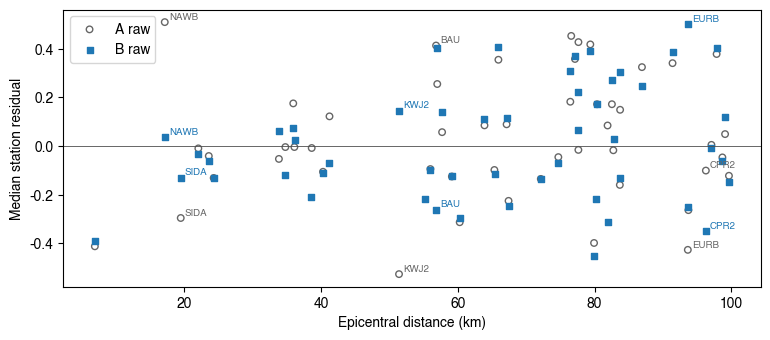

In [4]:
def loo(s):
    rows = []
    for eid, g in s.groupby('eid'):
        if len(g) < 4: continue
        for i, r in g.iterrows(): rows.append(dict(eid=eid, station=r.station, dist_km=r.dist_km, res=r.ml - g.drop(i).ml.median()))
    return pd.DataFrame(rows)
kma = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', dtype={'event_id': str})
cnt, res = [], {}
for k in V:
    e = ev[k]; res[k] = loo(st[k]); kk = e[e.template_match.isin(kma.event_id)].merge(kma[['event_id', 'ML']].rename(columns={'event_id': 'template_match'}), on='template_match')
    d3 = (kk.ml_min3 - kk.ML).dropna()
    cnt.append(dict(variant=k, ML_ge3=int(e.ml_min3.notna().sum()), ML_ge1=int(e.ml_min1.notna().sum()), KMA_with_primary=len(d3), primary_minus_KMA_median=d3.median(), primary_minus_KMA_RMS=float(np.sqrt(np.mean(d3 ** 2))) if len(d3) else np.nan,
                    network_MAD=(res[k].res - res[k].res.median()).abs().median()))
cnt = pd.DataFrame(cnt).set_index('variant'); display(cnt.round(3))
S_FOCUS = sorted(set(diff.trace_id.str.split('.').str[1]) | {'NAWB', 'KWJ2', 'EURB', 'SIDA'})
tab = pd.concat({k: r.groupby('station').res.agg(['size', 'median']) for k, r in res.items()}, axis=1)
tab['dist_km'] = res['A raw'].groupby('station').dist_km.median()
display(tab.loc[[s for s in S_FOCUS if s in tab.index]].round(2))
fig, ax = plt.subplots(figsize=(9, 3.6))
for k, c, mk in (('A raw', '0.4', 'o'), ('B raw', 'tab:blue', 's')):
    g = res[k].groupby('station').agg(m=('res', 'median'), d=('dist_km', 'median'))
    ax.scatter(g.d, g.m, color=c, marker=mk, s=22, label=k, facecolor='none' if k == 'A raw' else c)
    for s in [s for s in S_FOCUS if s in g.index]: ax.annotate(s, (g.loc[s, 'd'], g.loc[s, 'm']), xytext=(3, 2), textcoords='offset points', fontsize=7, color=c)
ax.axhline(0, color='0.3', lw=0.6); ax.set_xlabel('Epicentral distance (km)'); ax.set_ylabel('Median station residual'); ax.legend(frameon=True); plt.show()

## 4. Effect on event magnitudes

any-station ML, B raw - A raw: median -0.037, 5-95 % -0.42 to +0.01 (n=19)
primary ML gained / lost going from A raw to B raw: 5 / 0


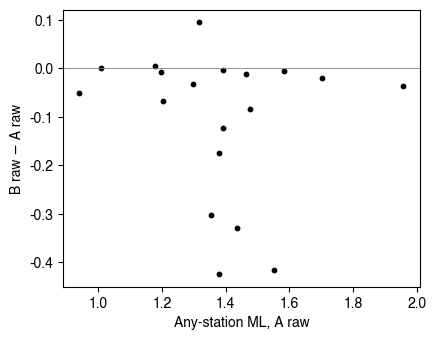

In [5]:
j = ev['A raw'][['eid', 'ml_min3', 'ml_min1', 'n_pick']].merge(ev['B raw'][['eid', 'ml_min3', 'ml_min1', 'n_pick']], on='eid', suffixes=('_A', '_B'))
j['d1'] = j.ml_min1_B - j.ml_min1_A
print(f'any-station ML, B raw - A raw: median {j.d1.median():+.3f}, 5-95 % {j.d1.quantile(.05):+.2f} to {j.d1.quantile(.95):+.2f} (n={j.d1.notna().sum()})')
print(f'primary ML gained / lost going from A raw to B raw: {int((j.ml_min3_A.isna() & j.ml_min3_B.notna()).sum())} / {int((j.ml_min3_A.notna() & j.ml_min3_B.isna()).sum())}')
fig, ax = plt.subplots(figsize=(4.6, 3.6)); ax.scatter(j.ml_min1_A, j.d1, s=10, color='black'); ax.axhline(0, color='0.5', lw=0.6)
ax.set_xlabel('Any-station ML, A raw'); ax.set_ylabel('B raw − A raw'); plt.show()

## Comprehensive summary

In [6]:
def stres(k, s): return f'{tab.loc[s, (k, "median")]:+.2f}' if s in tab.index and np.isfinite(tab.loc[s, (k, 'median')]) else 'n/a'
summary = pd.DataFrame([
    ('Channel-dates where RESP and master differ by > 0.05 ML at 5 Hz', f'{len(diff)} ({", ".join(sorted(set(diff.trace_id)))})'),
    ('RESP epochs raising the warning / integration correct', f'{int(dev.warned.sum())} of {len(dev)} / {integration_ok}'),
    ('Primary ML count: A / A raw / B raw', ' / '.join(str(cnt.loc[k, 'ML_ge3']) for k in V)),
    ('Primary ML - KMA ML median: A / A raw / B raw', ' / '.join(f'{cnt.loc[k, "primary_minus_KMA_median"]:+.2f}' for k in V)),
    ('Network MAD of station residuals: A raw / B raw', f'{cnt.loc["A raw", "network_MAD"]:.2f} / {cnt.loc["B raw", "network_MAD"]:.2f}'),
    *[(f'{s} residual: A raw / B raw', f'{stres("A raw", s)} / {stres("B raw", s)}') for s in ['NAWB', 'KWJ2', 'EURB', 'SIDA']],
    ('Any-station ML change B raw - A raw (median)', f'{j.d1.median():+.3f}'),
], columns=['quantity', 'value'])
display(summary)
print('Decisions this notebook informs (user):')
print('  D18 - keep the literal Haenam quarantine, or replace the warning-text test with the integration test of section 2.')
print('  D4  - master_first or resp_current; the station residuals of the channels in section 1 are the deciding evidence.')

,quantity,value
0,Channel-dates where RESP and master differ by ...,"36 (KS.BAU..ELE, KS.BAU..ELN, KS.BAU..ELZ, KS...."
1,RESP epochs raising the warning / integration ...,162 of 162 / True
2,Primary ML count: A / A raw / B raw,8 / 9 / 14
3,Primary ML - KMA ML median: A / A raw / B raw,-0.13 / -0.14 / -0.22
4,Network MAD of station residuals: A raw / B raw,0.18 / 0.18
5,NAWB residual: A raw / B raw,+0.51 / +0.04
6,KWJ2 residual: A raw / B raw,-0.53 / +0.15
7,EURB residual: A raw / B raw,-0.43 / +0.50
8,SIDA residual: A raw / B raw,-0.30 / -0.13
9,Any-station ML change B raw - A raw (median),-0.037


Decisions this notebook informs (user):
  D18 - keep the literal Haenam quarantine, or replace the warning-text test with the integration test of section 2.
  D4  - master_first or resp_current; the station residuals of the channels in section 1 are the deciding evidence.
